# YOLO26-OBB на VEDAI: дотренування та порівняння ініціалізацій

## 1. Colab Requirements

In [ ]:
!pip install -q ultralytics tensorboard


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import csv, copy, itertools, json, math, platform, random, shutil, statistics, subprocess, time
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict
from pathlib import Path

import matplotlib.pyplot as plt
import yaml
from PIL import Image, ImageDraw, ImageFont


## 2. Config

In [ ]:
RAW_ROOT = Path("/content/raw")  # розпакований VEDAI
DATA_DIR = Path("/content/datasets/vedai")  # датасет у форматі YOLO-OBB
RUNS_DIR = Path("/content/drive/MyDrive/obb-aerial/runs")  # прогони на Drive

DATA_CFG = {
    "rgb_suffix": "_co",
    "images_dir": None,  # None = автопошук
    "annotations": None,  # None = автопошук

    # id класу VEDAI -> назва, порядок = індекс класу YOLO
    "classes": {1: "car", 2: "truck", 4: "tractor", 5: "camping_car",
                # 7: "motorcycle", 8: "bus",  # замало даних (4 та 3 об'єкти)
                 9: "van", 10: "other", 11: "pickup", 23: "boat", 31: "plane"},
    "min_side_px": 2,  # відкидаємо вироджені рамки
    "centroid_tol_px": 3,  # допуск для перевірки центру рамки

    # що робити зі знімками з поганими рядками: drop_image / keep_image
    "bad_line_policy": "drop_image",
    "missing_ann_policy": "drop_image",
    "excluded_class_policy": "drop_image",

    "splits": {"n_folds": 10, "val_fraction": 0.15, "seed": 0, "stratify": True, "official_folds_dir": None},
}

## 3. Dataset VEDAI (1024)


In [ ]:
!mkdir -p /content/raw
!wget -nc -q -P /content/raw https://downloads.greyc.fr/vedai/Annotations1024.tar
!for i in 1 2 3 4 5; do wget -nc -q -P /content/raw https://downloads.greyc.fr/vedai/Vehicules1024.tar.00$i; done
!tar -xf /content/raw/Annotations1024.tar -C /content/raw
!cat /content/raw/Vehicules1024.tar.00* | tar -x -C /content/raw
!ls /content/raw


Annotations1024      Vehicules1024.tar.001  Vehicules1024.tar.004
Annotations1024.tar  Vehicules1024.tar.002  Vehicules1024.tar.005
Vehicules1024	     Vehicules1024.tar.003


## 4. VEDAI -> YOLO-OBB (format)

In [ ]:
# рядок анотації VEDAI: x_center y_center angle class_id is_contained is_occluded x1 x2 x3 x4 y1 y2 y3 y4

IMG_EXT = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
PALETTE = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8", "#f58231", "#911eb4",
           "#46f0f0", "#f032e6", "#bcf60c", "#fabebe", "#008080", "#9a6324"]


def show(path):
    try:
        from IPython.display import display
        display(Image.open(path))
    except Exception:
        print("Збережено:", path)


def get_font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()


def norm_id(s):
    s = Path(str(s)).stem
    for suf in ("_co", "_ir"):
        if s.endswith(suf):
            s = s[: -len(suf)]
    return s.zfill(8) if s.isdigit() else s


def raw_paths(cfg=DATA_CFG):
    img_dir, ann_dir = cfg["images_dir"], cfg["annotations"]
    if img_dir is None or ann_dir is None:
        imgs = Counter(p.parent for p in RAW_ROOT.rglob(f"*{cfg['rgb_suffix']}.*") if p.suffix.lower() in IMG_EXT)
        anns = Counter(p.parent for p in RAW_ROOT.rglob("*.txt") if p.stem.isdigit())

        def pick(c):
            pool = [d for d in c if "1024" in str(d)] or list(c)
            return max(pool, key=lambda d: c[d]) if pool else None
        img_dir = img_dir or pick(imgs)
        ann_dir = ann_dir or pick(anns)
    if img_dir is None or ann_dir is None:
        raise SystemExit(f"Не знайдено знімки/анотації в {RAW_ROOT}")
    return Path(img_dir), Path(ann_dir)


def _floats(line):
    try:
        return [float(x) for x in line.split()]
    except ValueError:
        return []


def parse_full_line(line, img_id):
    v = _floats(line)
    if len(v) != 14:
        return None
    return {"img_id": img_id, "xc": v[0], "yc": v[1], "angle": v[2], "cls": int(v[3]),
            "contained": int(v[4]), "occluded": int(v[5]), "xs": v[6:10], "ys": v[10:14], "raw": line.strip()}


def load_annotations(ann_dir, tol=3.0):
    """читає анотації: повні об'єкти (14 чисел) і погані рядки"""
    files = [p for p in sorted(Path(ann_dir).rglob("*.txt")) if p.stem.isdigit()]
    if not files:
        raise SystemExit(f"У {ann_dir} немає файлів 00000000.txt")
    ann, bad = {}, []
    for f in files:
        img_id = norm_id(f.stem)
        full, short = [], []
        for line in f.read_text().splitlines():
            if not line.strip():
                continue
            rec = parse_full_line(line, img_id)
            (full if rec else short).append(rec or line.strip())
        ann[img_id] = full
        for line in short:
            v = _floats(line)
            matched = len(v) >= 2 and any(abs(v[0] - o["xc"]) <= tol and abs(v[1] - o["yc"]) <= tol for o in full)
            bad.append({"img_id": img_id, "file": f.name, "n_tokens": len(line.split()), "line": line, "matched": matched})
    return ann, bad


def list_images(images_dir, rgb_suffix):
    return {norm_id(p.stem): p for p in sorted(Path(images_dir).rglob("*"))
            if p.suffix.lower() in IMG_EXT and p.stem.endswith(rgb_suffix)}


def report_bad_lines(bad, ann_dir, n_files):
    if not bad:
        print("Рядків не у форматі з 14 чисел: 0")
        return
    files = {b["file"] for b in bad}
    print(f"\n!!! Рядків не у форматі з 14 чисел: {len(bad)} у {len(files)} з {n_files} файлів")
    for n_tok, cnt in sorted(Counter(b["n_tokens"] for b in bad).items()):
        ex = [b for b in bad if b["n_tokens"] == n_tok][:3]
        dup = sum(b["matched"] for b in bad if b["n_tokens"] == n_tok)
        print(f"  {n_tok} чисел у рядку: {cnt} рядків, з них дублюють центр повного об'єкта: {dup}")
        for b in ex:
            print(f"     {b['file']}: {b['line']!r}")
    unmatched = [b for b in bad if not b["matched"]]
    print(f"Рядків, що НЕ дублюють жодного повного об'єкта: {len(unmatched)} у {len({b['img_id'] for b in unmatched})} знімках")
    first = bad[0]["file"]
    print(f"\nВміст першого проблемного файлу {first}:")
    print((Path(ann_dir) / first).read_text()[:1200])


def peek_images(ids, cfg=DATA_CFG, n=6, size=380):
    img_dir, _ = raw_paths(cfg)
    images = list_images(img_dir, cfg["rgb_suffix"])
    ids = sorted(ids)[:n]
    cols = min(3, len(ids))
    sheet = Image.new("RGB", (cols * size, math.ceil(len(ids) / cols) * size), (25, 25, 25))
    dr = ImageDraw.Draw(sheet)
    for j, i in enumerate(ids):
        sheet.paste(Image.open(images[i]).convert("RGB").resize((size, size)), ((j % cols) * size, (j // cols) * size))
        dr.text(((j % cols) * size + 6, (j // cols) * size + 4), i, fill="#ffe119", font=get_font(18))
    path = DATA_DIR / "viz" / "no_annotation_examples.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    sheet.save(path)
    show(path)


def plot_counts(path, overall, images_with=None, split_counts=None, split_title=""):
    order = sorted(overall, key=lambda c: -overall[c])
    n_panels = 1 + int(split_counts is not None or images_with is not None)
    fig, axes = plt.subplots(1, n_panels, figsize=(6.5 * n_panels, 0.45 * len(order) + 2.2))
    axes = [axes] if n_panels == 1 else list(axes)
    bars = axes[0].barh(order, [overall[c] for c in order], color="#4363d8")
    axes[0].invert_yaxis(); axes[0].set_xlabel("кількість об'єктів")
    axes[0].set_title(f"Об'єкти по класах (усього {sum(overall.values())})")
    axes[0].bar_label(bars, padding=3); axes[0].margins(x=0.12)
    if split_counts is not None:
        ax, left = axes[1], [0] * len(order)
        for part, col in zip(("train", "val", "test"), ("#4363d8", "#f58231", "#3cb44b")):
            vals = [split_counts[part].get(c, 0) for c in order]
            ax.barh(order, vals, left=left, color=col, label=part)
            for i, (v, l) in enumerate(zip(vals, left)):
                if v > 0:
                    ax.text(l + v / 2, i, str(v), ha="center", va="center", fontsize=8, color="white")
            left = [a + b for a, b in zip(left, vals)]
        ax.invert_yaxis(); ax.set_title(split_title or "train / val / test"); ax.legend()
    elif images_with is not None:
        bars = axes[1].barh(order, [images_with.get(c, 0) for c in order], color="#3cb44b")
        axes[1].invert_yaxis(); axes[1].set_title("Знімків, де клас зустрічається")
        axes[1].bar_label(bars, padding=3); axes[1].margins(x=0.12)
    fig.tight_layout()
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=130)
    plt.close(fig)


def class_gallery(ann, images, classes, k, path, seed=0, win=96, scale=3):
    by_cls = defaultdict(list)
    for recs in ann.values():
        for o in recs:
            by_cls[o["cls"]].append(o)
    ids = list(classes) + sorted(set(by_cls) - set(classes))
    rng, cell, label_w, font = random.Random(seed), win * scale, 230, get_font(20)
    sheet = Image.new("RGB", (label_w + k * cell, len(ids) * cell), (25, 25, 25))
    dr = ImageDraw.Draw(sheet)
    for r, cid in enumerate(ids):
        recs = [o for o in by_cls.get(cid, []) if o["img_id"] in images]
        dr.text((10, r * cell + cell // 2 - 24), f"id {cid}", fill="white", font=font)
        dr.text((10, r * cell + cell // 2), f"{classes.get(cid, 'НЕ В КОНФІГУ')}  (n={len(by_cls.get(cid, []))})",
                fill="#ffe119", font=font)
        for j, o in enumerate(rng.sample(recs, min(k, len(recs)))):
            im = Image.open(images[o["img_id"]]).convert("RGB")
            cx, cy = int(o["xc"]), int(o["yc"])
            box = (cx - win // 2, cy - win // 2, cx + win // 2, cy + win // 2)
            crop = im.crop(box).resize((cell, cell), Image.LANCZOS)
            poly = [((x - box[0]) * scale, (y - box[1]) * scale) for x, y in zip(o["xs"], o["ys"])]
            ImageDraw.Draw(crop).polygon(poly, outline="#ffe119", width=2)
            sheet.paste(crop, (label_w + j * cell, r * cell))
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    sheet.save(path)


def inspect_raw(cfg=DATA_CFG, examples=3):
    """діагностика сирих даних"""
    classes, tol = cfg["classes"], cfg["centroid_tol_px"]
    img_dir, ann_dir = raw_paths(cfg)
    print("Знімки:", img_dir, "\nАнотації:", ann_dir)
    ann, bad = load_annotations(ann_dir, tol)
    images = list_images(img_dir, cfg["rgb_suffix"])
    n_obj = sum(len(v) for v in ann.values())
    print(f"\nФайлів анотацій: {len(ann)} | RGB-знімків: {len(images)} | повних об'єктів (14 чисел): {n_obj}")
    print("Анотації без знімка:", len(set(ann) - set(images)), "| знімки без файлу анотацій:", len(set(images) - set(ann)))
    report_bad_lines(bad, ann_dir, len(ann))
    no_ann = sorted(set(images) - set(ann))
    if no_ann:
        print(f"\nЗнімки БЕЗ файлу анотацій ({len(no_ann)}): {no_ann[:20]}")
        print("Подивіться, чи є на них транспорт (no_annotation_examples.png). Якщо є, їх не можна брати як 'фон'.")
        peek_images(no_ann, cfg)
    excl = {c for v in ann.values() for o in v for c in [o["cls"]] if c not in classes}
    if excl:
        n_img = len({o["img_id"] for v in ann.values() for o in v if o["cls"] not in classes})
        print(f"\nКласи поза конфігом {sorted(excl)}: знімків із такими об'єктами {n_img} (політика: {cfg['excluded_class_policy']})")

    counts = Counter(o["cls"] for v in ann.values() for o in v)
    img_counts = Counter(c for v in ann.values() for c in {o["cls"] for o in v})
    print("\nid -> об'єктів / знімків (назва з конфігу):")
    for cid, n in sorted(counts.items()):
        print(f"  {cid:>3}: {n:>5} / {img_counts[cid]:>4}   {classes.get(cid, 'НЕ В КОНФІГУ (буде відкинуто)')}")
    print("Класи з конфігу, яких немає в даних:", [c for c in classes if c not in counts] or "немає")

    print("\nПо одному прикладу кожного класу (id -> назва -> індекс YOLO):")
    idx, rng = {cid: i for i, cid in enumerate(classes)}, random.Random(0)
    for cid in sorted(counts):
        o = rng.choice([o for v in ann.values() for o in v if o["cls"] == cid])
        print(f"  id {cid:>2} -> {classes.get(cid, '???'):<12} idx={idx.get(cid, '-')}  знімок {o['img_id']}")
        print(f"       рядок: {o['raw']}")

    bad_c = sum(abs(sum(o["xs"]) / 4 - o["xc"]) > tol or abs(sum(o["ys"]) / 4 - o["yc"]) > tol
                for v in ann.values() for o in v)
    maxc = max((max(*o["xs"], *o["ys"]) for v in ann.values() for o in v), default=0)
    print(f"\nПеревірка формату: {bad_c}/{n_obj} об'єктів, де центр != центр чотирьох кутів (допуск {tol}px)")
    if images:
        w, h = Image.open(next(iter(images.values()))).size
        print(f"Макс. координата: {maxc:.0f}, розмір знімка: {w}x{h}")

    out = DATA_DIR / "viz"
    nm = {c: classes.get(c, f"id{c}?") for c in counts}
    plot_counts(out / "class_counts_raw.png", {nm[c]: n for c, n in counts.items()},
                images_with={nm[c]: n for c, n in img_counts.items()})
    class_gallery(ann, images, classes, examples, out / "class_examples.png")
    show(out / "class_counts_raw.png")
    show(out / "class_examples.png")
    print("Подивитися class_examples.png: у кожному рядку мають бути об'єкти, що відповідають назві класу.")


def poly_sides(pts):
    s1, s2 = math.dist(pts[0], pts[1]), math.dist(pts[1], pts[2])
    return max(s1, s2), min(s1, s2)


def _stratum(per_image, ids):
    freq = Counter(c for i in ids for c in per_image[i])
    return {i: (min(per_image[i], key=lambda c: (freq[c], c)) if per_image[i] else "_background") for i in ids}


def _spread(strata_groups, n, rng):
    buckets, offset = [[] for _ in range(n)], 0
    for s_name in sorted(strata_groups, key=lambda k: (len(strata_groups[k]), str(k))):
        lst = sorted(strata_groups[s_name])
        rng.shuffle(lst)
        for j, i in enumerate(lst):
            buckets[(offset + j) % n].append(i)
        offset += len(lst)
    return buckets


def make_folds(ids, scfg, per_image=None):
    """розбиття на фолди train/val/test"""
    n_folds, seed, off = scfg["n_folds"], scfg["seed"], scfg.get("official_folds_dir")
    strat = bool(scfg.get("stratify")) and per_image is not None and not off
    id_set, folds = set(ids), {}
    strata = _stratum(per_image, ids) if strat else {i: "all" for i in ids}
    if off:
        def read(p):
            return [norm_id(l.split()[0]) for l in Path(p).read_text().splitlines() if l.strip()]
        for k in range(1, n_folds + 1):
            pool = [i for i in read(Path(off) / f"fold{k:02d}.txt") if i in id_set]
            test = [i for i in read(Path(off) / f"fold{k:02d}test.txt") if i in id_set]
            assert not (set(pool) & set(test)), f"fold {k}: train-пул і test перетинаються"
            folds[k] = {"pool": pool, "test": test}
    else:
        groups = defaultdict(list)
        for i in ids:
            groups[strata[i]].append(i)
        chunks = _spread(groups, n_folds, random.Random(seed))
        for k in range(1, n_folds + 1):
            folds[k] = {"test": chunks[k - 1], "pool": [i for j, c in enumerate(chunks) if j != k - 1 for i in c]}
    for k, f in folds.items():
        rng = random.Random(seed * 1000 + k)
        by_s = defaultdict(list)
        for i in f["pool"]:
            by_s[strata[i]].append(i)
        val = []
        for lst in by_s.values():  # val з кожної страти (стратифікація по класах)
            lst = sorted(lst)
            rng.shuffle(lst)
            n_val = round(scfg["val_fraction"] * len(lst))
            val += lst[: max(n_val, 1) if len(lst) >= 2 else n_val]
        f["val"] = sorted(val)
        f["train"] = sorted(set(f["pool"]) - set(val))
        f["test"] = sorted(f["test"])
        del f["pool"]
    return folds


def convert_dataset(cfg=DATA_CFG, plot_fold=1):
    """сирі дані -> датасет YOLO-OBB + фолди"""
    out, classes = DATA_DIR, cfg["classes"]
    cls_index = {cid: i for i, cid in enumerate(classes)}
    names = {i: classes[cid] for cid, i in cls_index.items()}
    tol, min_side = cfg["centroid_tol_px"], cfg["min_side_px"]
    img_dir, ann_dir = raw_paths(cfg)
    ann, bad = load_annotations(ann_dir, tol)
    images = list_images(img_dir, cfg["rgb_suffix"])
    if not images:
        raise SystemExit(f"Не знайдено знімків із суфіксом {cfg['rgb_suffix']} у {img_dir}")

    drops = {"bad_lines": set(), "no_annotation_file": set(), "excluded_class": set()}
    if cfg["bad_line_policy"] == "drop_image":
        drops["bad_lines"] = {b["img_id"] for b in bad if not b["matched"]}
    if cfg["missing_ann_policy"] == "drop_image":
        drops["no_annotation_file"] = set(images) - set(ann)
    if cfg["excluded_class_policy"] == "drop_image":
        drops["excluded_class"] = {i for i, recs in ann.items() if any(o["cls"] not in cls_index for o in recs)}
    drop_ids = set().union(*drops.values())
    report_bad_lines(bad, ann_dir, len(ann))
    print("Викинуто знімків:", {k: len(v) for k, v in drops.items()}, "| разом унікальних:", len(drop_ids))

    for sub in ("images", "labels", "meta", "viz"):  # чистить старі результати
        shutil.rmtree(out / sub, ignore_errors=True)
        (out / sub).mkdir(parents=True, exist_ok=True)
    for p in list(out.glob("fold*_*.txt")) + list(out.glob("vedai_fold*.yaml")) + [out / "labels.cache"]:
        p.unlink(missing_ok=True)

    dropped, unknown_ids, sizes = Counter(), Counter(), defaultdict(list)
    per_image, meta_rows, n_empty, centroid_bad, max_ratio = {}, [], 0, 0, 0.0
    kept_images = {i: p for i, p in images.items() if i not in drop_ids}

    for img_id, img_path in sorted(kept_images.items()):
        w, h = Image.open(img_path).size
        dst = out / "images" / f"{img_id}.png"
        if img_path.suffix.lower() == ".png":
            shutil.copy2(img_path, dst)
        else:
            Image.open(img_path).convert("RGB").save(dst)
        lines, per_image[img_id] = [], Counter()
        for o in ann.get(img_id, []):
            if o["cls"] not in cls_index:
                dropped["unknown_class"] += 1
                unknown_ids[o["cls"]] += 1
                continue
            if abs(sum(o["xs"]) / 4 - o["xc"]) > tol or abs(sum(o["ys"]) / 4 - o["yc"]) > tol:
                centroid_bad += 1
            max_ratio = max(max_ratio, max(o["xs"]) / w, max(o["ys"]) / h)
            cx, cy = sum(o["xs"]) / 4, sum(o["ys"]) / 4
            if not (0 <= cx < w and 0 <= cy < h):
                dropped["center_outside"] += 1
                continue
            pts = [(min(max(x, 0.0), w), min(max(y, 0.0), h)) for x, y in zip(o["xs"], o["ys"])]
            long_s, short_s = poly_sides(pts)
            if short_s < min_side:
                dropped["degenerate"] += 1
                continue
            if any(x < 0 or x > w or y < 0 or y > h for x, y in zip(o["xs"], o["ys"])):
                dropped["clipped_to_border(kept)"] += 1
            ci = cls_index[o["cls"]]
            lines.append(f"{ci} " + " ".join(f"{x / w:.6f} {y / h:.6f}" for x, y in pts))
            sizes[names[ci]].append(long_s)
            per_image[img_id][names[ci]] += 1
            meta_rows.append({"image_id": img_id, "obj_idx": len(lines) - 1, "orig_class_id": o["cls"],
                              "class_idx": ci, "class_name": names[ci], "occluded": o["occluded"],
                              "contained": o["contained"], "long_side_px": round(long_s, 2),
                              "short_side_px": round(short_s, 2), "angle_rad": o["angle"]})
        n_empty += not lines
        (out / "labels" / f"{img_id}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
    if not meta_rows:
        raise SystemExit("Жодного об'єкта не збережено: перевір класи й формат (inspect_raw).")

    with open(out / "meta" / "objects.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=list(meta_rows[0]))
        wr.writeheader(); wr.writerows(meta_rows)

    folds = make_folds(sorted(kept_images), cfg["splits"], per_image)
    split_counts = {}
    for k, f in folds.items():
        split_counts[k] = {}
        for part in ("train", "val", "test"):
            (out / f"fold{k:02d}_{part}.txt").write_text("\n".join(f"./images/{i}.png" for i in f[part]) + "\n")
            c = Counter()
            for i in f[part]:
                c.update(per_image[i])
            split_counts[k][part] = dict(c)
        (out / f"vedai_fold{k:02d}.yaml").write_text(yaml.safe_dump(
            {"train": f"fold{k:02d}_train.txt", "val": f"fold{k:02d}_val.txt",
             "test": f"fold{k:02d}_test.txt", "names": names}, sort_keys=False, allow_unicode=True))

    overall = Counter(r["class_name"] for r in meta_rows)
    missing = {k: {p: [n for n in names.values() if split_counts[k][p].get(n, 0) == 0] for p in ("val", "test")}
               for k in folds}
    stats = {"n_images_kept": len(kept_images), "n_images_dropped": {k: len(v) for k, v in drops.items()},
             "n_images_without_objects": n_empty, "n_objects_kept": len(meta_rows),
             "bad_lines_total": len(bad), "bad_lines_unmatched": sum(not b["matched"] for b in bad),
             "objects_per_class": dict(overall), "dropped": dict(dropped), "unknown_class_ids": dict(unknown_ids),
             "centroid_mismatch_objects": centroid_bad, "max_coord_over_image_size": round(max_ratio, 3),
             "long_side_px": {c: {"median": round(statistics.median(v), 1), "min": round(min(v), 1),
                                  "max": round(max(v), 1)} for c, v in sizes.items()},
             "folds": {k: {p: len(f[p]) for p in ("train", "val", "test")} for k, f in folds.items()},
             "class_counts_per_split": split_counts, "classes_missing_in_split": missing}
    (out / "meta" / "stats.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False))
    plot_counts(out / "meta" / "class_counts.png", dict(overall), split_counts=split_counts[plot_fold],
                split_title=f"fold{plot_fold:02d}: train / val / test")
    print(json.dumps({k: stats[k] for k in ("n_images_kept", "n_images_dropped", "n_images_without_objects",
                                            "n_objects_kept", "objects_per_class", "dropped", "unknown_class_ids")},
                     indent=2, ensure_ascii=False))
    bad_folds = {k for k, v in missing.items() if v["val"] or v["test"]}
    if bad_folds:
        print(f"\nУВАГА: у {len(bad_folds)} з {len(folds)} фолдів є класи без жодного об'єкта у val/test "
              f"(AP для них не визначений). Деталі: meta/stats.json -> classes_missing_in_split.")
    if centroid_bad > 0.05 * len(meta_rows):
        print("УВАГА: багато об'єктів із розбіжністю центру; перевір формат (inspect_raw).")
    show(out / "meta" / "class_counts.png")
    return stats


def viz_labels(n=12, cfg=DATA_CFG):
    out, names = DATA_DIR, dict(enumerate(cfg["classes"].values()))
    stems = sorted(p.stem for p in (out / "labels").glob("*.txt") if p.stat().st_size > 0)
    random.Random(0).shuffle(stems)
    tiles = []
    for s in stems[:n]:
        im = Image.open(out / "images" / f"{s}.png").convert("RGB")
        w, h = im.size
        dr = ImageDraw.Draw(im)
        for line in (out / "labels" / f"{s}.txt").read_text().splitlines():
            v = line.split()
            ci, pts = int(v[0]), [float(x) for x in v[1:]]
            poly = [(pts[i] * w, pts[i + 1] * h) for i in range(0, 8, 2)]
            col = PALETTE[ci % len(PALETTE)]
            dr.polygon(poly, outline=col, width=2)
            dr.text((poly[0][0] + 2, poly[0][1] + 2), names.get(ci, str(ci)), fill=col)
        tiles.append(im.resize((512, 512)))
    cols = 4
    grid = Image.new("RGB", (cols * 512, math.ceil(len(tiles) / cols) * 512))
    for i, t in enumerate(tiles):
        grid.paste(t, ((i % cols) * 512, (i // cols) * 512))
    grid.save(out / "viz" / "label_check.png")
    show(out / "viz" / "label_check.png")


Знімки: /content/raw/Vehicules1024 
Анотації: /content/raw/Annotations1024

Файлів анотацій: 1250 | RGB-знімків: 1268 | повних об'єктів (14 чисел): 3757
Анотації без знімка: 0 | знімки без файлу анотацій: 18

!!! Рядків не у форматі з 14 чисел: 31 у 4 з 1250 файлів
  5 чисел у рядку: 31 рядків, з них дублюють центр повного об'єкта: 0
     00000341.txt: '33.627178 17.925803 11 1 0'
     00000341.txt: '76.011814 69.658656 10 1 0'
     00000341.txt: '88.150288 97.771474 11 1 0'
Рядків, що НЕ дублюють жодного повного об'єкта: 31 у 4 знімках

Вміст першого проблемного файлу 00000341.txt:
33.627178 17.925803 11 1 0
76.011814 69.658656 10 1 0
88.150288 97.771474 11 1 0
109.115708 124.000938 2 1 0
128.265939 146.690786 10 1 0
143.150479 164.116589 1 1 0
162.391470 214.578810 2 1 0
86.279887 205.067909 11 1 0
100.892149 224.127381 11 1 0
74.118129 182.922617 11 1 0
253.881372 320.769934 11 1 0


Знімки БЕЗ файлу анотацій (18): ['00000024', '00000028', '00000034', '00000039', '00000424', '000004

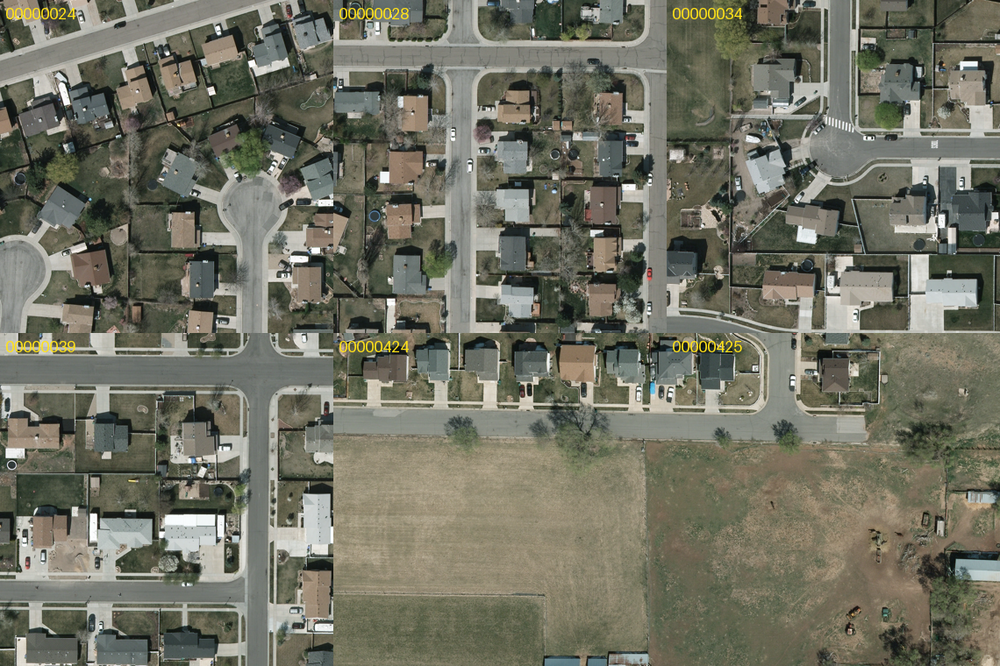


Класи поза конфігом [7, 8]: знімків із такими об'єктами 7 (політика: drop_image)

id -> об'єктів / знімків (назва з конфігу):
    1:  1377 /  698   car
    2:   307 /  216   truck
    4:   190 /  149   tractor
    5:   397 /  266   camping_car
    7:     4 /    4   НЕ В КОНФІГУ (буде відкинуто)
    8:     3 /    3   НЕ В КОНФІГУ (буде відкинуто)
    9:   101 /   88   van
   10:   204 /  138   other
   11:   955 /  604   pickup
   23:   171 /  134   boat
   31:    48 /   20   plane
Класи з конфігу, яких немає в даних: немає

По одному прикладу кожного класу (id -> назва -> індекс YOLO):
  id  1 -> car          idx=0  знімок 00000654
       рядок: 402.487675 622.065693 2.132718 1 1 0 404 418 398 390 603 614 638 633
  id  2 -> truck        idx=1  знімок 00000817
       рядок: 870.491967 834.813994 -1.499850 2 1 0 867 888 877 850 736 737 935 932
  id  4 -> tractor      idx=2  знімок 00000073
       рядок: 207.701030 357.462667 0.024995 4 1 0 187 228 227 188 342 342 374 372
  id  5 -> camp

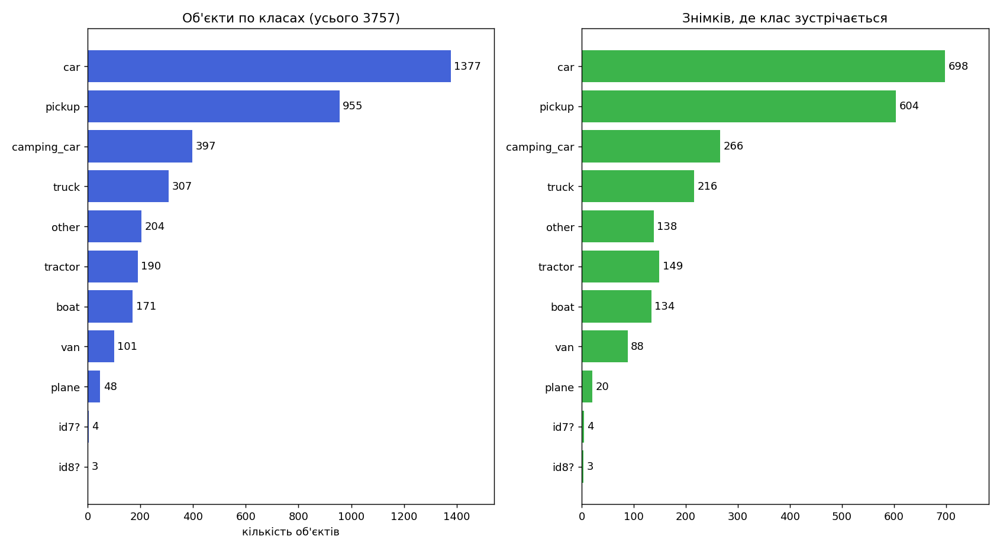

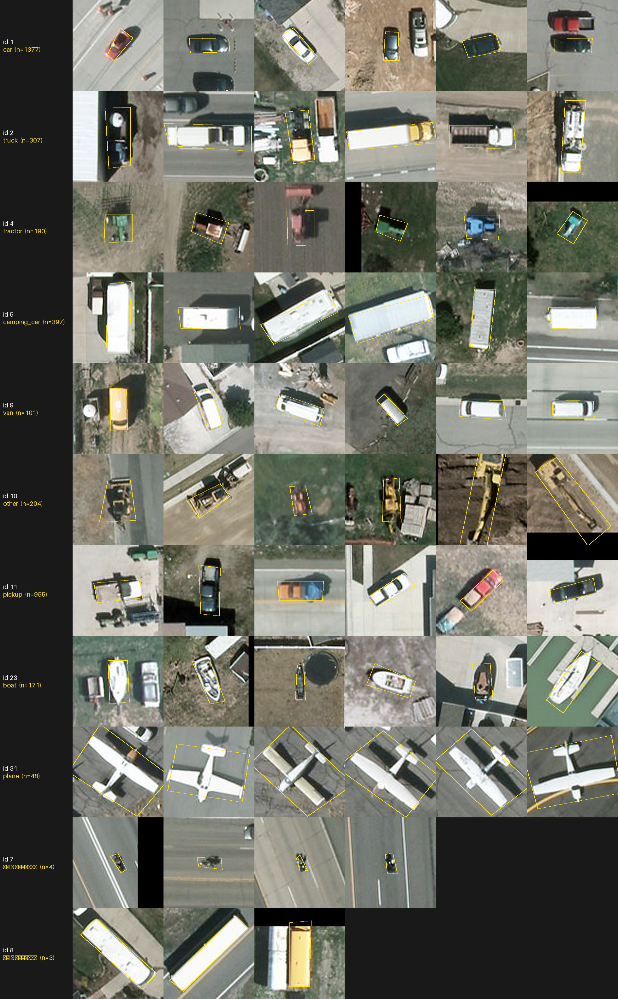

Подивіться class_examples.png: у кожному рядку мають бути об'єкти, що відповідають назві класу.


In [ ]:
# перевірка датасету
inspect_raw(examples=6)




!!! Рядків не у форматі з 14 чисел: 31 у 4 з 1250 файлів
  5 чисел у рядку: 31 рядків, з них дублюють центр повного об'єкта: 0
     00000341.txt: '33.627178 17.925803 11 1 0'
     00000341.txt: '76.011814 69.658656 10 1 0'
     00000341.txt: '88.150288 97.771474 11 1 0'
Рядків, що НЕ дублюють жодного повного об'єкта: 31 у 4 знімках

Вміст першого проблемного файлу 00000341.txt:
33.627178 17.925803 11 1 0
76.011814 69.658656 10 1 0
88.150288 97.771474 11 1 0
109.115708 124.000938 2 1 0
128.265939 146.690786 10 1 0
143.150479 164.116589 1 1 0
162.391470 214.578810 2 1 0
86.279887 205.067909 11 1 0
100.892149 224.127381 11 1 0
74.118129 182.922617 11 1 0
253.881372 320.769934 11 1 0

Викинуто знімків: {'bad_lines': 4, 'no_annotation_file': 18, 'excluded_class': 7} | разом унікальних: 29
{
  "n_images_kept": 1239,
  "n_images_dropped": {
    "bad_lines": 4,
    "no_annotation_file": 18,
    "excluded_class": 7
  },
  "n_images_without_objects": 0,
  "n_objects_kept": 3718,
  "objects_per_

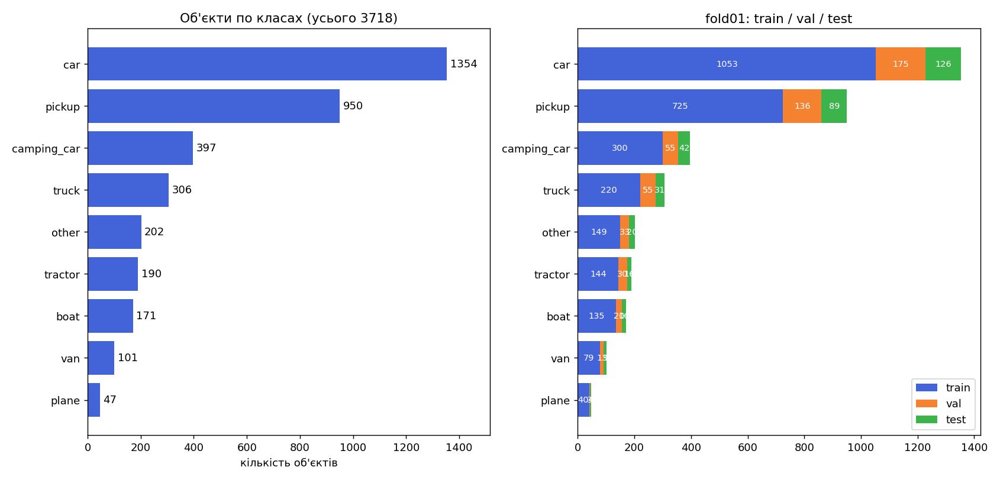

In [ ]:
# конвертація + фолди

stats = convert_dataset()


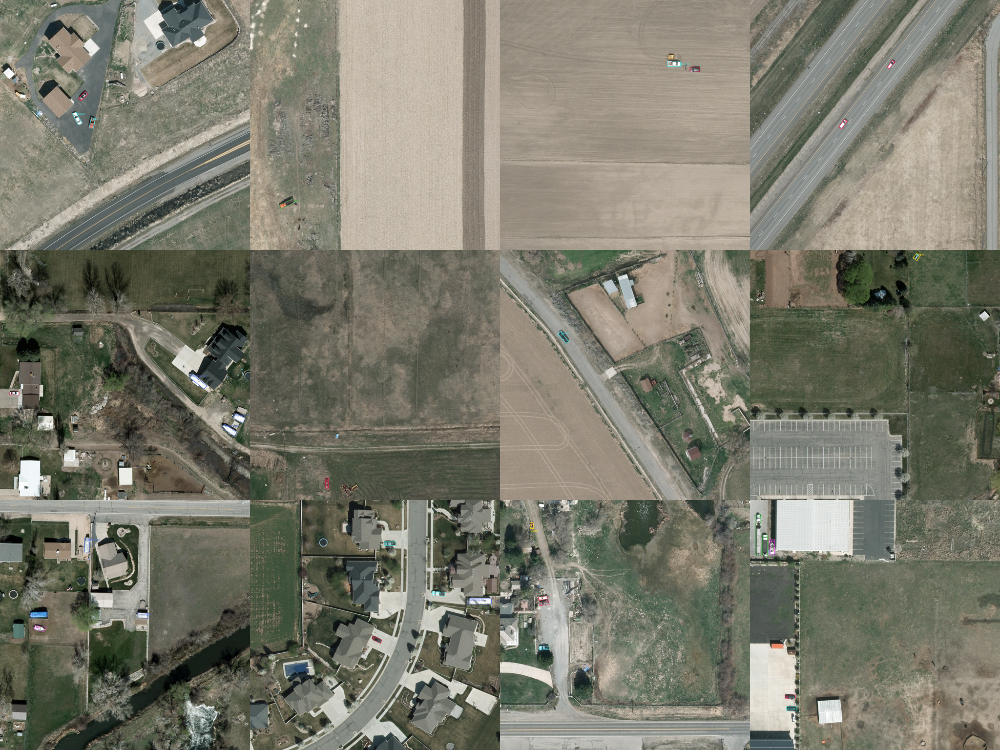

In [ ]:
# візуальна перевірка розмітки
viz_labels(12)


## 5. Pipeline

| init | старт | режим |
|---|---|---|
| `zeroshot` | `yolo26{s}-obb.pt` (DOTA) | без тренування, лише оцінка |
| `scratch` | `yolo26{s}-obb.yaml` | один етап, з нуля |
| `coco` | той самий yaml + ваги `yolo26{s}.pt` (OBB-голова нова) | один етап |
| `dota_frozen` | `yolo26{s}-obb.pt` | один етап, backbone заморожений |
| `dota_unfrozen` | `yolo26{s}-obb.pt` | етап 1: backbone заморожений, етап 2: розморожено з меншим lr |

Оцінка в двох протоколах (обидва пишуться в `summary.json`):
1. `fine` (`final`): 9 класів VEDAI. Для `zeroshot` класи DOTA зводяться до одного представника (`small vehicle` -> `car` тощо), решта класів AP = 0
2. `coarse` (`final_coarse`): 4 спільні класи DOTA (`small vehicle`, `large vehicle`, `ship`, `plane`), щоб чесно порівняти з zero-shot

In [ ]:
import os

import torch

# fine: 9 класів VEDAI; coarse: 4 спільні класи DOTA (чесне порівняння з zero-shot)
EVAL_CFG = {
    # клас VEDAI -> клас DOTA (None = відповідника немає)
    "vedai_to_dota": {"car": "small vehicle", "pickup": "small vehicle", "van": "small vehicle",
                      "camping_car": "small vehicle", "tractor": "small vehicle",
                      "truck": "large vehicle", "boat": "ship", "plane": "plane", "other": None},
    # клас DOTA -> один клас VEDAI (zero-shot у fine-протоколі)
    "dota_to_vedai": {"small vehicle": "car", "large vehicle": "truck", "ship": "boat", "plane": "plane"},
}
COARSE_CLASSES = list(dict.fromkeys(v for v in EVAL_CFG["vedai_to_dota"].values() if v))


def coarse_root(data_root):
    data_root = Path(data_root)
    return data_root.parent / f"{data_root.name}_coarse"


def build_coarse_dataset(data_root=DATA_DIR, cfg=EVAL_CFG, verbose=True):
    """копія датасету з мітками в coarse-класах"""
    src, dst = Path(data_root), coarse_root(data_root)
    yamls = sorted(src.glob("*_fold*.yaml"))
    if not yamls:
        raise SystemExit(f"У {src} немає *_foldNN.yaml: спершу convert_dataset()")
    fine_names = {int(k): v for k, v in yaml.safe_load(yamls[0].read_text())["names"].items()}
    unknown = sorted(set(fine_names.values()) - set(cfg["vedai_to_dota"]))
    if unknown:
        raise ValueError(f"Класи без рядка в EVAL_CFG['vedai_to_dota']: {unknown} (додайте назву DOTA або None)")
    idx = {i: (COARSE_CLASSES.index(cfg["vedai_to_dota"][n]) if cfg["vedai_to_dota"][n] else None)
           for i, n in fine_names.items()}
    labels = sorted((src / "labels").glob("*.txt"))
    stamp = {"mapping": cfg["vedai_to_dota"], "fine_names": {str(k): v for k, v in fine_names.items()},
             "n_labels": len(labels), "labels_mtime": max((p.stat().st_mtime for p in labels), default=0),
             "yamls": [y.name for y in yamls]}
    stamp_path = dst / "stamp.json"
    if stamp_path.exists() and json.loads(stamp_path.read_text()) == stamp:
        return dst
    shutil.rmtree(dst, ignore_errors=True)
    (dst / "labels").mkdir(parents=True)
    os.symlink(src / "images", dst / "images", target_is_directory=True)  # знімки не копіюємо
    kept, dropped = Counter(), Counter()
    for p in labels:
        out = []
        for line in p.read_text().splitlines():
            ci, rest = line.split(maxsplit=1)
            name = fine_names[int(ci)]
            if idx[int(ci)] is None:
                dropped[name] += 1
            else:
                kept[COARSE_CLASSES[idx[int(ci)]]] += 1
                out.append(f"{idx[int(ci)]} {rest}")
        (dst / "labels" / p.name).write_text("\n".join(out) + ("\n" if out else ""))
    for p in src.glob("fold*_*.txt"):
        shutil.copy2(p, dst / p.name)
    for y in yamls:
        d = yaml.safe_load(y.read_text())
        d["names"] = dict(enumerate(COARSE_CLASSES))
        (dst / y.name).write_text(yaml.safe_dump(d, sort_keys=False, allow_unicode=True))
    stamp_path.write_text(json.dumps(stamp, indent=2, ensure_ascii=False))
    if verbose:
        print(f"coarse-датасет: {dst}\n  об'єктів по класах: {dict(kept)}\n  відкинуто (без відповідника): {dict(dropped)}")
    return dst


def class_lut(model_names, target_names, mapping):
    tgt = {str(v).strip().lower(): int(k) for k, v in target_names.items()}
    lut = []
    for i in range(len(model_names)):
        name = model_names[i]
        name = mapping.get(name, name)
        lut.append(tgt.get(str(name).strip().lower(), -1) if name else -1)
    return torch.tensor(lut, dtype=torch.long)


def remap_validator(model_names, target_names, mapping):
    """валідатор, що переводить класи моделі в класи датасету"""
    from ultralytics.models.yolo.obb import OBBValidator
    from ultralytics.utils.metrics import ConfusionMatrix

    lut = class_lut(model_names, target_names, mapping)
    names = {int(k): v for k, v in target_names.items()}

    class RemapOBBValidator(OBBValidator):
        def init_metrics(self, model):
            super().init_metrics(model)  # nc лишається числом класів моделі
            self.names = self.metrics.names = names
            self.confusion_matrix = ConfusionMatrix(names=names, task="obb")

        def postprocess(self, preds):
            out = []
            for p in super().postprocess(preds):
                cls = lut.to(p["cls"].device)[p["cls"].long()]
                order = torch.argsort(p["conf"], descending=True)
                order = order[cls[order] >= 0]
                p = {k: v[order] for k, v in p.items()}
                cls = cls[order]
                if len(cls) > 1:
                    key = torch.cat([p["bboxes"], cls[:, None].to(p["bboxes"].dtype)], dim=1)
                    _, inv = torch.unique(key, dim=0, return_inverse=True)
                    pos = torch.arange(len(inv), device=inv.device)
                    first = torch.full((int(inv.max()) + 1,), len(inv), device=inv.device).scatter_reduce(0, inv, pos, "amin")
                    keep = torch.sort(first).values  # лишаємо найвпевненіший дубль
                    p, cls = {k: v[keep] for k, v in p.items()}, cls[keep]
                p["cls"] = cls.to(p["conf"].dtype)
                out.append(p)
            return out

    return RemapOBBValidator


def zeroshot_class_affinity(size="s", fold=1, split="train", conf=0.25, imgsz=1024, batch=8,
                            model_family="yolo26", data_root=DATA_DIR, dataset="vedai"):
    """у які класи DOTA zero-shot модель відносить класи VEDAI"""
    import pandas as pd
    data_yaml = Path(data_root) / f"{dataset}_fold{fold:02d}.yaml"
    fine = {int(k): v for k, v in yaml.safe_load(data_yaml.read_text())["names"].items()}
    model = YOLO(f"{model_family}{size}-obb.pt")
    m = model.val(data=str(data_yaml), split=split, imgsz=imgsz, batch=batch, conf=conf, plots=True, verbose=False,
                  project=str(Path(data_root) / "viz"), name="zeroshot_affinity", exist_ok=True)
    mat = m.confusion_matrix.matrix
    rows = [model.names[i] for i in range(len(model.names))] + ["пропущено"]
    df = pd.DataFrame(mat[:, :len(fine)], index=rows, columns=[fine[i] for i in range(len(fine))])
    df = df.loc[df.sum(axis=1) > 0]
    share = (df / df.sum(axis=0).clip(lower=1)).round(2)
    share.loc["n об'єктів"] = df.sum(axis=0).astype(int)
    return share


In [ ]:
from ultralytics import YOLO, settings

INITS = ("scratch", "coco", "dota_frozen", "dota_unfrozen")
ZERO_SHOT = "zeroshot"  # без тренування, лише оцінка
SIZES = ("n", "s", "m", "l", "x")


def deep_merge(base, new):
    out = copy.deepcopy(base)
    for k, v in new.items():
        out[k] = deep_merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else copy.deepcopy(v)
    return out


@dataclass
class RunConfig:
    init: str = "dota_unfrozen"  # scratch | coco | dota_frozen | dota_unfrozen | zeroshot
    size: str = "n"
    seed: int = 0  # seed тренування (не розбиття)
    fold: int = 1
    dataset: str = "vedai"
    model_family: str = "yolo26"
    data_root: str = str(DATA_DIR)
    out_root: str = str(RUNS_DIR)
    tag: str = ""
    freeze: int = 11  # backbone = шари 0..10 (C2PSA = 10)
    epochs: dict = field(default_factory=lambda: {"stage1": 20, "stage2": 30})  # stage1 + stage2
    train: dict = field(default_factory=lambda: {
        "imgsz": 1024, "batch": 8, "optimizer": "AdamW", "lr0": 0.001,  # optimizer явно: 'auto' ігнорує lr0
        "warmup_bias_lr": 0.0,  # 0.1 розраховане на SGD, для AdamW забагато
        "flipud": 0.5, "close_mosaic": 5, "workers": 2, "patience": 100, "plots": True})
    stage_overrides: dict = field(default_factory=lambda: {"stage2": {"lr0": 0.0005}})
    eval_splits: list = field(default_factory=lambda: ["val", "test"])

    def __post_init__(self):
        if self.init not in INITS + (ZERO_SHOT,):
            raise ValueError(f"init має бути одним із {INITS + (ZERO_SHOT,)}, отримано {self.init!r}")
        if self.size not in SIZES:
            raise ValueError(f"size має бути одним із {SIZES}, отримано {self.size!r}")

    @classmethod
    def from_overrides(cls, **kw):
        unknown = set(kw) - set(cls.__dataclass_fields__)
        if unknown:
            raise ValueError(f"Невідомі параметри: {sorted(unknown)}")
        return cls(**deep_merge(asdict(cls()), kw))

    @property
    def total_epochs(self):
        return int(self.epochs["stage1"]) + int(self.epochs["stage2"])

    @property
    def run_id(self):
        return f"{self.dataset}/{self.model_family}{self.size}/{self.init}{self.tag}/fold{self.fold:02d}_seed{self.seed}"

    @property
    def data_yaml(self):
        return Path(self.data_root) / f"{self.dataset}_fold{self.fold:02d}.yaml"


@dataclass
class Stage:
    name: str
    epochs: int
    freeze: int = None


def make_plan(cfg):
    s1, s2, total = int(cfg.epochs["stage1"]), int(cfg.epochs["stage2"]), cfg.total_epochs
    if cfg.init == ZERO_SHOT:
        return []
    if cfg.init in ("scratch", "coco"):
        return [Stage("full", total, None)]
    if cfg.init == "dota_frozen":
        return [Stage("frozen", total, cfg.freeze)]
    return [Stage("stage1", s1, cfg.freeze), Stage("stage2", s2, None)]


def tb_writer(log_dir):
    try:
        from torch.utils.tensorboard import SummaryWriter
    except Exception:
        from tensorboardX import SummaryWriter
    Path(log_dir).mkdir(parents=True, exist_ok=True)
    return SummaryWriter(str(log_dir), flush_secs=30, filename_suffix=f".{time.time_ns()}")


def epochs_completed(stage_dir):
    csv_path = Path(stage_dir) / "results.csv"
    return max(0, len(csv_path.read_text().strip().splitlines()) - 1) if csv_path.exists() else 0


class Run:
    """один прогін: етапи тренування + оцінка"""

    def __init__(self, cfg):
        self.cfg, self.plan = cfg, make_plan(cfg)
        self.run_dir = Path(cfg.out_root) / cfg.run_id
        self.stage_info = {}

    summary_path = property(lambda self: self.run_dir / "summary.json")
    is_done = lambda self: self.summary_path.exists()

    def describe(self):
        lines = [f"run_id: {self.cfg.run_id}", f"dir:    {self.run_dir}", f"data:   {self.cfg.data_yaml}"]
        for s in self.plan:
            a = self._stage_args(s)
            lines.append(f"  stage {s.name:<7} epochs={s.epochs:<3} freeze={s.freeze} lr0={a.get('lr0')} optimizer={a.get('optimizer')}")
        if not self.plan:
            lines.append(f"  без тренування: оцінка {self.cfg.model_family}{self.cfg.size}-obb.pt (fine + coarse)")
        return "\n".join(lines)

    def _init_model(self):
        c, arch = self.cfg, f"{self.cfg.model_family}{self.cfg.size}"
        if c.init == "scratch":
            return YOLO(f"{arch}-obb.yaml")
        if c.init == "coco":
            return YOLO(f"{arch}-obb.yaml").load(f"{arch}.pt")
        return YOLO(f"{arch}-obb.pt")

    def _stage_args(self, stage):
        c = self.cfg
        args = {**c.train, **c.stage_overrides.get(stage.name, {})}
        args.update(data=str(c.data_yaml), epochs=stage.epochs, seed=c.seed,
                    project=str(self.run_dir), name=stage.name, exist_ok=True)
        if stage.freeze:
            args["freeze"] = stage.freeze
        if c.init == "scratch":
            args["pretrained"] = False
        return args

    def _run_stage(self, idx, stage, offset, prev_best, writer):
        sdir = self.run_dir / stage.name
        flag = sdir / "stage_done.json"
        if flag.exists():
            print(f"[{self.cfg.run_id}] етап {stage.name}: уже завершений, пропуск")
            return json.loads(flag.read_text())
        best, last = sdir / "weights" / "best.pt", sdir / "weights" / "last.pt"
        info, t0 = {"epochs": stage.epochs, "freeze": stage.freeze}, time.time()

        def on_train_start(trainer):
            ps = list(trainer.model.parameters())
            info["trainable_params"] = sum(p.numel() for p in ps if p.requires_grad)
            info["total_params"] = sum(p.numel() for p in ps)
            print(f"[{stage.name}] trainable {info['trainable_params']:,} / {info['total_params']:,} params")
            # writer.add_scalar(f"params/trainable_{stage.name}", info["trainable_params"], offset)

        def on_fit_epoch_end(trainer):
            step, scalars = offset + trainer.epoch + 1, {}
            for getter in (lambda: trainer.label_loss_items(trainer.tloss, prefix="train"),
                           lambda: trainer.metrics, lambda: trainer.lr):
                try:
                    scalars.update(getter())
                except Exception:
                    pass
            for k, v in scalars.items():
                try:
                    writer.add_scalar(k, float(v), step)
                except Exception:
                    pass
            # writer.add_scalar("stage/index", idx, step)

        done_epochs = epochs_completed(sdir)
        if done_epochs >= stage.epochs and (best.exists() or last.exists()):
            print(f"[{self.cfg.run_id}] етап {stage.name}: усі епохи вже в results.csv, позначено як done")
        else:
            resume = last.exists()
            if resume:
                print(f"[{self.cfg.run_id}] етап {stage.name}: відновлення з last.pt ({done_epochs}/{stage.epochs} епох)")
                model = YOLO(str(last))
            else:
                model = self._init_model() if idx == 0 else YOLO(str(prev_best))
            model.add_callback("on_train_start", on_train_start)
            model.add_callback("on_fit_epoch_end", on_fit_epoch_end)
            model.train(resume=True) if resume else model.train(**self._stage_args(stage))

        info.update(seconds=round(time.time() - t0, 1), best=str(best if best.exists() else last),
                    epochs_completed=epochs_completed(sdir))
        sdir.mkdir(parents=True, exist_ok=True)
        flag.write_text(json.dumps(info, indent=2))
        return info

    @staticmethod
    def _metrics_to_dict(m):
        box = m.box
        d = {"mAP50": float(box.map50), "mAP50-95": float(box.map), "precision": float(box.mp),
             "recall": float(box.mr), "per_class": {}}
        try:
            for i, c in enumerate(box.ap_class_index):
                d["per_class"][m.names[int(c)]] = {"AP50": float(box.ap50[i]), "AP50-95": float(box.ap[i]),
                                                   "P": float(box.p[i]), "R": float(box.r[i])}
        except Exception as e:
            d["per_class_error"] = repr(e)
        try:
            d["confusion_matrix"] = m.confusion_matrix.matrix.tolist()
            d["confusion_matrix_names"] = [m.names[i] for i in sorted(m.names)] + ["background"]
        except Exception as e:
            d["confusion_matrix_error"] = repr(e)
        return d

    def _val(self, model, data_yaml, split, name, validator=None):
        c = self.cfg
        kw = dict(data=str(data_yaml), split=split, imgsz=c.train.get("imgsz", 1024), batch=c.train.get("batch", 8),
                  workers=c.train.get("workers", 2), project=str(self.run_dir), name=name, exist_ok=True,
                  plots=True, seed=c.seed)
        if validator is not None:
            kw["validator"] = validator
        return self._metrics_to_dict(model.val(**kw))

    def _evaluate(self, weights, writer, step):
        c, model = self.cfg, YOLO(str(weights))
        zs = c.init == ZERO_SHOT
        fine_names = {int(k): v for k, v in yaml.safe_load(c.data_yaml.read_text())["names"].items()}
        coarse_yaml = build_coarse_dataset(c.data_root, verbose=False) / c.data_yaml.name
        protocols = {
            "fine": (c.data_yaml, remap_validator(model.names, fine_names, EVAL_CFG["dota_to_vedai"]) if zs else None,
                     "final", "eval"),
            "coarse": (coarse_yaml, remap_validator(model.names, dict(enumerate(COARSE_CLASSES)),
                                                    {} if zs else EVAL_CFG["vedai_to_dota"]),
                       "final_coarse", "eval_coarse"),
        }
        out = {}
        for proto, (data_yaml, validator, tb, folder) in protocols.items():
            out[proto] = {}
            for split in c.eval_splits:
                d = out[proto][split] = self._val(model, data_yaml, split, f"{folder}_{split}", validator)
                # for k in ("mAP50", "mAP50-95", "precision", "recall"):
                #     writer.add_scalar(f"{tb}/{split}/{k}", d[k], step)
                self._log_per_class(writer, f"{tb}_per_class/{split}", d["per_class"], step)
        return out

    @staticmethod
    def _log_per_class(writer, tag, per_class, step):
        if not per_class:
            return
        names = list(per_class)
        fig, ax = plt.subplots(figsize=(max(5.0, 0.9 * len(names) + 2), 3.6))
        for off, key in ((-0.2, "AP50"), (0.2, "AP50-95")):
            bars = ax.bar([i + off for i in range(len(names))], [per_class[n][key] for n in names], 0.4, label=key)
            ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
        ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
        ax.set_ylim(0, 1.08); ax.set_title(tag); ax.legend()
        fig.tight_layout()
        writer.add_figure(tag, fig, step)
        rows = "\n".join(f"| {n} | {v['AP50']:.3f} | {v['AP50-95']:.3f} | {v['P']:.3f} | {v['R']:.3f} |"
                         for n, v in per_class.items())
        writer.add_text(tag, "| клас | AP50 | AP50-95 | P | R |\n|---|---|---|---|---|\n" + rows, step)

    def _check_config(self):
        """зупиняємось, якщо в теці вже є прогін з іншим конфігом"""
        path = self.run_dir / "config.yaml"
        if not path.exists():
            return
        old, new = yaml.safe_load(path.read_text()) or {}, asdict(self.cfg)
        diff = sorted(k for k in new if k not in ("eval_splits", "out_root", "data_root") and k in old and old[k] != new[k])
        if diff:
            raise RuntimeError(f"[{self.cfg.run_id}] у {self.run_dir} уже є прогін з іншим конфігом (відрізняється: {diff}). "
                               f"Задайте інший tag (напр. tag='_ep100') або видаліть теку прогону.")

    def _write_env(self):
        env = {"python": platform.python_version()}
        for mod in ("ultralytics", "torch"):
            try:
                env[mod] = __import__(mod).__version__
            except Exception:
                env[mod] = None
        (self.run_dir / "env.json").write_text(json.dumps(env, indent=2))

    def execute(self, force=False):
        """force=True: повторити лише фінальну оцінку"""
        if self.is_done() and not force:
            print(f"[{self.cfg.run_id}] уже завершений, пропуск")
            return json.loads(self.summary_path.read_text())
        self._check_config()
        self.run_dir.mkdir(parents=True, exist_ok=True)
        cfg_yaml = yaml.safe_dump(asdict(self.cfg), sort_keys=False, allow_unicode=True)
        (self.run_dir / "config.yaml").write_text(cfg_yaml)
        self._write_env()
        try:  # свій TB-логер замість вбудованого
            settings.update({"tensorboard": False})
        except Exception:
            pass
        writer = tb_writer(self.run_dir / "tb")
        writer.add_text("config", "```yaml\n" + cfg_yaml + "\n```", 0)
        t0, offset, prev_best = time.time(), 0, None
        try:
            for i, st in enumerate(self.plan):
                self.stage_info[st.name] = self._run_stage(i, st, offset, prev_best, writer)
                prev_best, offset = Path(self.stage_info[st.name]["best"]), offset + st.epochs
            if self.cfg.init == ZERO_SHOT:
                prev_best = f"{self.cfg.model_family}{self.cfg.size}-obb.pt"
            final = self._evaluate(prev_best, writer, step=offset)
        finally:
            writer.flush(); writer.close()
        summary = {"run_id": self.cfg.run_id, "config": asdict(self.cfg), "stages": self.stage_info,
                   "total_seconds": round(time.time() - t0, 1), "final": final["fine"], "final_coarse": final["coarse"],
                   "eval_cfg": EVAL_CFG}
        self.summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
        return summary


def run_grid(inits=("dota_unfrozen",), sizes=("n",), seeds=(0,), folds=(1,), dry_run=False, force=False, **overrides):
    """сітка init x size x fold x seed"""
    # zeroshot детермінований: seed завжди 0
    combos = dict.fromkeys((i, s, f, 0 if i == ZERO_SHOT else sd) for i, s, f, sd in itertools.product(inits, sizes, folds, seeds))
    runs = [Run(RunConfig.from_overrides(init=i, size=s, fold=f, seed=sd, **overrides)) for i, s, f, sd in combos]
    print(f"Прогонів у сітці: {len(runs)}\n")
    for r in runs:
        print(f"[{'DONE' if r.is_done() else 'todo'}] {r.describe()}\n")
    if dry_run:
        return runs
    for n, r in enumerate(runs, 1):
        print(f"===== {n}/{len(runs)}: {r.cfg.run_id} =====")
        r.execute(force=force)
    return runs

## 6. Dry-run, smoke-тест
dry_run - показує план без запуску, smoke-тест - перевірка запуску тренування

In [ ]:
run_grid(inits=(ZERO_SHOT,) + INITS, sizes=["n"], seeds=[0], dry_run=True)

In [ ]:
smoke = dict(out_root="/content/runs_smoke", tag="_smoke", epochs={"stage1": 1, "stage2": 1},
             train={"imgsz": 320, "batch": 4, "workers": 0, "plots": False})
run_grid(inits=["dota_unfrozen"], sizes=["n"], seeds=[0], folds=[1], **smoke)
run_grid(inits=[ZERO_SHOT], sizes=["n"], folds=[1], **smoke)


## 7. Zero-shot baseline і повна сітка

In [ ]:
# спочатку zero-shot: DOTA-ваги оцінюються на VEDAI без тренування
# zeroshot_class_affinity() = у які класи DOTA модель відносить об'єкти VEDAI (перевірка мапінгу)

# далі всі чотири ініціалізації, розміри й seed-и додати в GRID

In [ ]:
GRID = dict(inits=list(INITS), sizes=["s"], seeds=[0], folds=[1])

# zero-shot baseline
run_grid(inits=[ZERO_SHOT], sizes=GRID["sizes"], folds=GRID["folds"])
zeroshot_class_affinity(size=GRID["sizes"][0], fold=GRID["folds"][0])


Прогонів у сітці: 1

[todo] run_id: vedai/yolo26s/zeroshot/fold01_seed0
dir:    /content/drive/MyDrive/obb-aerial/runs/vedai/yolo26s/zeroshot/fold01_seed0
data:   /content/datasets/vedai/vedai_fold01.yaml
  без тренування: оцінка yolo26s-obb.pt (fine + coarse)

===== 1/1: vedai/yolo26s/zeroshot/fold01_seed0 =====
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s-obb summary (fused): 129 layers, 9,756,972 parameters, 0 gradients, 21.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4723.8±452.8 MB/s, size: 1831.3 KB)
val: Scanning /content/datasets/vedai/labels... 168 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 168/168 366.6it/s 0.5s
val: New cache created: /content/datasets/vedai/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 1.8it/s 11.5s
                   all        168        520      0.228      0.211      0.224      0.189
                   car

,car,truck,tractor,camping_car,van,other,pickup,boat,plane
plane,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.92
ship,0.01,0.02,0.00,0.00,0.00,0.00,0.03,0.36,0.00
harbor,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.00
large vehicle,0.06,0.22,0.00,0.02,0.37,0.00,0.09,0.00,0.00
small vehicle,0.43,0.00,0.00,0.00,0.06,0.01,0.09,0.00,0.00
swimming pool,0.00,0.00,0.01,0.01,0.00,0.00,0.00,0.03,0.00
пропущено,0.49,0.76,0.99,0.97,0.57,0.99,0.80,0.61,0.08
n об'єктів,1053.00,220.00,144.00,300.00,79.00,149.00,725.00,135.00,40.00


In [ ]:
run_grid(**GRID)


Прогонів у сітці: 4

[todo] run_id: vedai/yolo26s/scratch/fold01_seed0
dir:    /content/drive/MyDrive/obb-aerial/runs/vedai/yolo26s/scratch/fold01_seed0
data:   /content/datasets/vedai/vedai_fold01.yaml
  stage full    epochs=50  freeze=None lr0=0.001 optimizer=AdamW

[todo] run_id: vedai/yolo26s/coco/fold01_seed0
dir:    /content/drive/MyDrive/obb-aerial/runs/vedai/yolo26s/coco/fold01_seed0
data:   /content/datasets/vedai/vedai_fold01.yaml
  stage full    epochs=50  freeze=None lr0=0.001 optimizer=AdamW

[todo] run_id: vedai/yolo26s/dota_frozen/fold01_seed0
dir:    /content/drive/MyDrive/obb-aerial/runs/vedai/yolo26s/dota_frozen/fold01_seed0
data:   /content/datasets/vedai/vedai_fold01.yaml
  stage frozen  epochs=50  freeze=11 lr0=0.001 optimizer=AdamW

[todo] run_id: vedai/yolo26s/dota_unfrozen/fold01_seed0
dir:    /content/drive/MyDrive/obb-aerial/runs/vedai/yolo26s/dota_unfrozen/fold01_seed0
data:   /content/datasets/vedai/vedai_fold01.yaml
  stage stage1  epochs=20  freeze=11 lr0=

## 8. TensorBoard
Кожен прогін це один ран `.../tb`, логи лежать на Drive.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /content/drive/MyDrive/obb-aerial/runs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 4263), started 4:54:52 ago. (Use '!kill 4263' to kill it.)

<IPython.core.display.Javascript object>

## 9. Результати: mean ± std по seed
`report()` збирає всі `summary.json` з `RUNS_DIR`, рахує mean ± std по seed-ах для обох протоколів і зберігає таблиці та графіки в `RUNS_DIR/_results/`.

Для висновків беремо `test`: на `val` вибирався `best.pt`, тому val-метрики трохи оптимістичні.

In [ ]:
import pandas as pd

METRICS = ["mAP50", "mAP50-95", "precision", "recall"]
GROUP = ["dataset", "model", "init"]


def collect_results(root=RUNS_DIR):
    """усі summary.json в одну таблицю"""
    rows = []
    for p in sorted(Path(root).glob("*/*/*/*/summary.json")):  # dataset/model/init/foldNN_seedS
        s = json.loads(p.read_text())
        c = s["config"]
        base = {"dataset": c["dataset"], "model": f"{c['model_family']}{c['size']}", "init": c["init"] + c.get("tag", ""),
                "fold": c["fold"], "seed": c["seed"],
                "epochs": sum(st.get("epochs_completed", 0) for st in s.get("stages", {}).values()),
                "train_min": round(s.get("total_seconds", 0) / 60, 1), "run_dir": str(p.parent)}
        for protocol, key in (("fine", "final"), ("coarse", "final_coarse")):
            for split, d in (s.get(key) or {}).items():
                row = {**base, "protocol": protocol, "split": split, **{m: d[m] for m in METRICS}}
                for cls, v in d.get("per_class", {}).items():
                    row[f"AP50/{cls}"], row[f"AP50-95/{cls}"] = v["AP50"], v["AP50-95"]
                rows.append(row)
    df = pd.DataFrame(rows)
    if df.empty:
        print(f"У {root} ще немає жодного summary.json")
    return df


def aggregate(df, split="test", protocol="fine", cols=METRICS, warn=True):
    """mean ± std по seed-ах"""
    d = df[(df["split"] == split) & (df["protocol"] == protocol)]
    if d.empty:
        return pd.DataFrame()
    cols = [c for c in cols if c in d.columns]
    for key, g in d.groupby(GROUP):
        fsets = g.groupby("seed")["fold"].agg(lambda s: tuple(sorted(s))).unique()
        if warn and len(fsets) > 1:
            print(f"УВАГА {key}: у seed-ів різні набори фолдів {list(fsets)}; середнє зміщене, дорахуйте сітку")
    per_seed = d.groupby(GROUP + ["seed"], as_index=False)[cols].mean()
    g = per_seed.groupby(GROUP)
    out = g[cols].agg(["mean", "std"])
    out.insert(0, ("n", "seeds"), g["seed"].nunique())
    out.insert(1, ("n", "folds"), d.groupby(GROUP)["fold"].nunique())
    out.insert(2, ("n", "runs"), d.groupby(GROUP).size())
    trained = out[out.index.get_level_values("init") != ZERO_SHOT]
    if warn and trained[("n", "seeds")].nunique() > 1:
        print("УВАГА: у груп різна кількість seed-ів; порівняння нерівноцінне, доки сітка не дорахована")
    return out


def pretty(agg, digits=3):
    if agg.empty:
        return agg
    out = agg["n"].copy()
    for m in [c for c in agg.columns.get_level_values(0).unique() if c != "n"]:
        mean, std = agg[(m, "mean")], agg[(m, "std")]
        out[m] = [f"{a:.{digits}f}" + (f" ± {b:.{digits}f}" if pd.notna(b) else "") for a, b in zip(mean, std)]
    return out


def per_class_table(df, split="test", protocol="fine", metric="AP50-95"):
    cols = [c for c in df.columns if c.startswith(f"{metric}/")]
    d = df[(df["split"] == split) & (df["protocol"] == protocol)]
    cols = [c for c in cols if d[c].notna().any()]
    agg = aggregate(df, split, protocol, cols, warn=False)
    if agg.empty:
        return agg
    out = agg.xs("mean", axis=1, level=1).drop(columns="n", errors="ignore")
    return out.rename(columns=lambda c: c.split("/", 1)[1]).round(3)


def delta_vs_zeroshot(df, split="test", metric="mAP50-95"):
    agg = aggregate(df, split, "coarse", [metric], warn=False)
    if agg.empty:
        return agg
    mean = agg[(metric, "mean")]
    base = mean[mean.index.get_level_values("init") == ZERO_SHOT].droplevel("init")
    if base.empty:
        print("Немає zero-shot прогонів: run_grid(inits=[ZERO_SHOT], ...)")
        return pd.DataFrame()
    out = pretty(agg)
    ref = [base.get(i[:2], float("nan")) for i in mean.index]
    out[f"Δ {metric} vs zero-shot"] = (mean.values - ref).round(3)
    return out


def plot_results(df, split="test", protocol="fine", metric="mAP50-95", path=None):
    d = df[(df["split"] == split) & (df["protocol"] == protocol)]
    agg = aggregate(df, split, protocol, [metric], warn=False)
    if agg.empty:
        return
    per_seed = d.groupby(GROUP + ["seed"], as_index=False)[metric].mean()
    inits = list(dict.fromkeys(agg.index.get_level_values("init")))
    models = list(dict.fromkeys(agg.index.get_level_values("model")))
    fig, ax = plt.subplots(figsize=(1.6 * len(inits) * max(len(models), 1) + 2.5, 4.2))
    width = 0.8 / len(models)
    for j, model in enumerate(models):
        for i, init in enumerate(inits):
            rows = agg[(agg.index.get_level_values("model") == model) & (agg.index.get_level_values("init") == init)]
            if rows.empty:
                continue
            x = i + (j - (len(models) - 1) / 2) * width
            mean, std = rows[(metric, "mean")].iloc[0], rows[(metric, "std")].iloc[0]
            ax.bar(x, mean, width * 0.9, yerr=None if pd.isna(std) else std, capsize=4,
                   color=PALETTE[(j + 3) % len(PALETTE)], label=model if i == 0 else None)
            pts = per_seed[(per_seed["model"] == model) & (per_seed["init"] == init)][metric]
            ax.scatter([x] * len(pts), pts, color="black", s=14, zorder=3)
            ax.annotate(f"{mean:.3f}", (x, mean + (0 if pd.isna(std) else std)), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(inits)), inits, rotation=15)
    ax.margins(y=0.15)
    ax.set_ylabel(f"{metric} ({split}, {protocol})")
    ax.set_title(f"{metric}: mean ± std по seed-ах (точки = окремі seed-и)")
    ax.legend(title="модель")
    fig.tight_layout()
    if path:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=130)
    plt.show()


def report(root=RUNS_DIR, split="test", save=True):
    """зведення по всіх завершених прогонах"""
    from IPython.display import display
    df = collect_results(root)
    if df.empty:
        return df
    out = Path(root) / "_results"
    if save:
        out.mkdir(parents=True, exist_ok=True)
        df.to_csv(out / "runs_long.csv", index=False)
    for protocol, title in (("fine", "fine: 9 класів VEDAI"), ("coarse", "coarse: суперкласи DOTA (порівняння з zero-shot)")):
        agg = aggregate(df, split, protocol)
        if agg.empty:
            continue
        print(f"\n=== {title} | split={split} | mean ± std по seed-ах ===")
        display(delta_vs_zeroshot(df, split) if protocol == "coarse" and (df["init"] == ZERO_SHOT).any() else pretty(agg))
        print(f"AP50-95 по класах ({protocol}, {split}), середнє по seed-ах:")
        display(per_class_table(df, split, protocol))
        if save:
            agg.to_csv(out / f"summary_{protocol}_{split}.csv")
            per_class_table(df, split, protocol).to_csv(out / f"per_class_{protocol}_{split}.csv")
        plot_results(df, split, protocol, path=(out / f"mAP50-95_{protocol}_{split}.png") if save else None)
    return df


In [ ]:
results = report(split="test")


# Commit and push results

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from google.colab import userdata
import subprocess, os

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
token = userdata.get("github_access_token")
print("Token found:", bool(token))


Token found: True


In [ ]:
# OBB-aerial repo

REPO = "U-Karpcova/OBB-aerial"
SRC  = "/content/drive/MyDrive/obb-aerial/runs"
DST  = "/content/repo"

token = userdata.get("github_access_token")

if not os.path.exists(DST):
    subprocess.run(
        ["git", "clone", f"https://{token}@github.com/{REPO}.git", DST],
        check=True
    )
else:
    subprocess.run(["git", "-C", DST, "pull", "--rebase"], check=True)

# оновити credentials для push
subprocess.run([
    "git", "-C", DST, "remote", "set-url",
    "origin", f"https://{token}@github.com/{REPO}.git"
], check=True)


In [ ]:
# без файлів >95 МБ
subprocess.run([
    "rsync", "-a", "--prune-empty-dirs",
    "--max-size=95m", "--exclude=_smoke",
    f"{SRC}/", f"{DST}/runs/",
], check=True)

def git(*args): subprocess.run(["git", "-C", DST, *args], check=True)
git("config", "user.email", "_") # вписати
git("config", "user.name", "_") # вписати
git("add", "runs")
subprocess.run(["git", "-C", DST, "commit", "-m", "Update experiment logs"])  # без check: нічого комітити - не помилка
git("push")

big = subprocess.run(["find", SRC, "-type", "f", "-size", "+95M", "-not", "-path", "*/_smoke/*"],
                     capture_output=True, text=True).stdout.split()
print("Пропущено (завеликі для GitHub):", *big, sep="\n  ") if big else print("Усі файли <95 МБ синхронізовано.")
